In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


In [ ]:
df = pd.read_csv("/content/housing.csv")
print("First 5 rows:")
print(df.head())


First 5 rows:
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  


In [ ]:
df.columns = df.columns.str.strip()
print("\nCleaned column names:")
print(df.columns.tolist())



Cleaned column names:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']


In [ ]:
print("\nDataset shape:")
print(df.shape)
print("\nDataset information:")
df.info()
print("\nStatistical summary:")
print(df.describe())



Dataset shape:
(20640, 10)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Statistical summary:
          longitude      latitude  housing_median_age   total_rooms  \
count  20640.000000  20640.000000        20640.000000  20640.000000   
mean    -119.569704     35.631861    

In [ ]:
print("\nMissing values:")
print(df.isnull().sum())
# Remove rows with missing values
df = df.dropna()
# Remove duplicate rows
df = df.drop_duplicates()
print("\nDataset shape after cleaning:")
print(df.shape)



Missing values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Dataset shape after cleaning:
(20433, 10)


In [ ]:
target = "median_house_value"
print("\nTarget variable:", target)



Target variable: median_house_value


In [ ]:
features = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income"
]

X = df[features]
y = df[target]
print("\nSelected features:")
print(features)
print("\nTarget:")
print(target)



Selected features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']

Target:
median_house_value


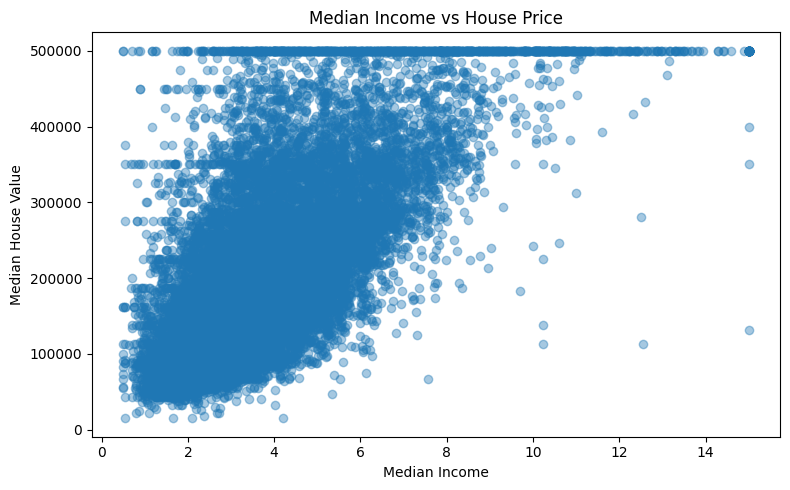

In [ ]:
# 8. PLOT 1 - HOUSE PRICE DISTRIBUTION
plt.figure(figsize=(8, 5))

plt.scatter(
    df["median_income"],
    df["median_house_value"],
    alpha=0.4
)

plt.title("Median Income vs House Price")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.tight_layout()
plt.show()

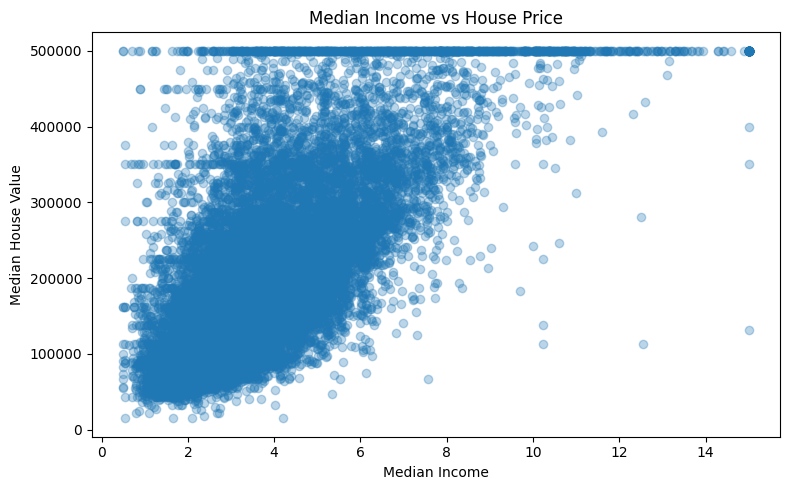

In [ ]:
# PLOT 2 - MEDIAN INCOME VS HOUSE PRICE

plt.figure(figsize=(8, 5))

plt.scatter(
    df["median_income"],
    df[target],
    alpha=0.3
)

plt.title("Median Income vs House Price")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.tight_layout()
plt.show()

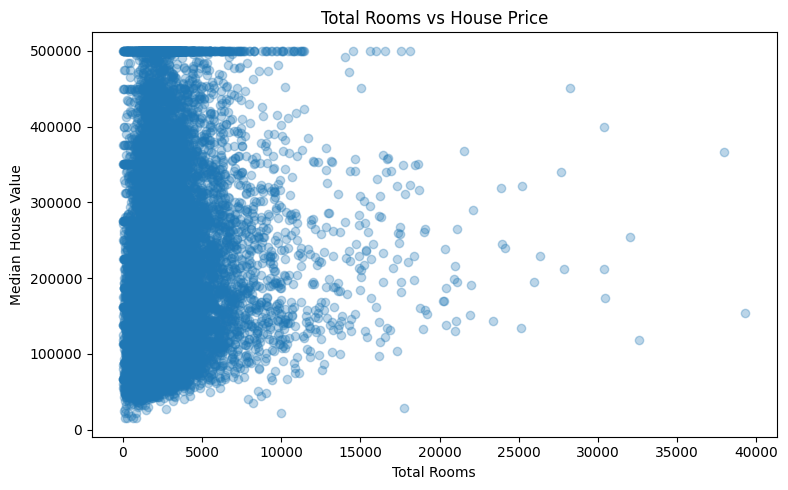

In [ ]:

#PLOT 3 - TOTAL ROOMS VS HOUSE PRICE
plt.figure(figsize=(8, 5))
plt.scatter(
    df["total_rooms"],
    df[target],
    alpha=0.3
)

plt.title("Total Rooms vs House Price")
plt.xlabel("Total Rooms")
plt.ylabel("Median House Value")

plt.tight_layout()
plt.show()


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)



Training data: (16346, 8)
Testing data: (4087, 8)


In [ ]:
model = LinearRegression()

In [ ]:
model.fit(X_train, y_train)
print("\nModel training completed!")




Model training completed!


In [ ]:
#Model prediction
y_pred = model.predict(X_test)

In [ ]:
#MODEL EVALUATION
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n")
print("MODEL EVALUATION")
print("")

print("RMSE:", rmse)
print("R2 Score:", r2)




MODEL EVALUATION

RMSE: 70156.120457364
R2 Score: 0.640086568899372


In [ ]:
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
})

print("\n")
print("FEATURE COEFFICIENTS")
print("")
print(coefficients)
print("\nIntercept:", model.intercept_)




FEATURE COEFFICIENTS

              Feature   Coefficient
0           longitude -42546.706006
1            latitude -42336.042987
2  housing_median_age   1155.097108
3         total_rooms     -8.440418
4      total_bedrooms    115.830375
5          population    -36.758767
6          households     41.640434
7       median_income  40293.278408

Intercept: -3569674.5266952454


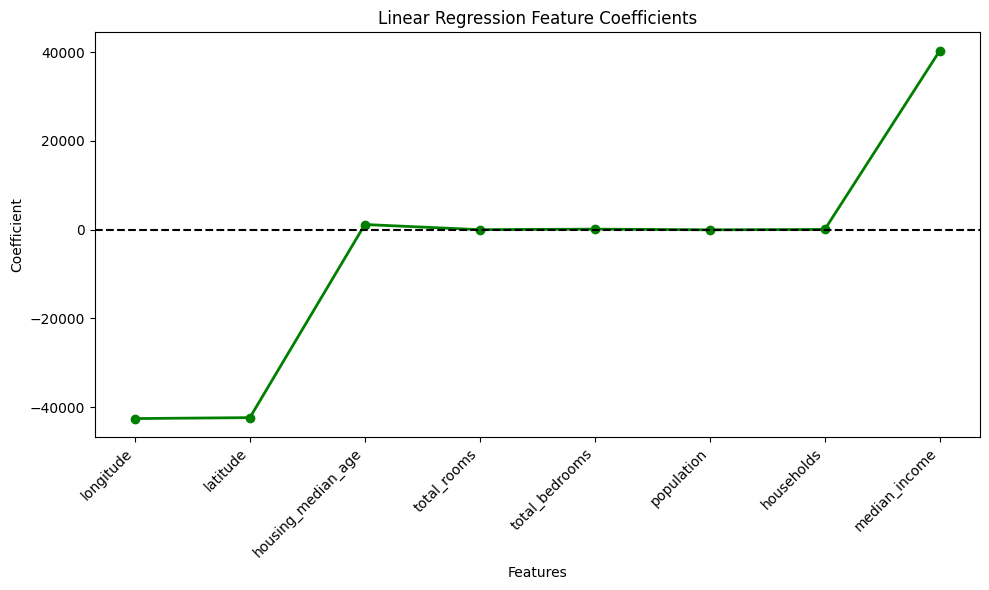

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    coefficients["Feature"],
    coefficients["Coefficient"],
    marker="o",
    linewidth=2,
    color="green"
)

plt.axhline(0, color="black", linestyle="--")

plt.title("Linear Regression Feature Coefficients")
plt.xlabel("Features")
plt.ylabel("Coefficient")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

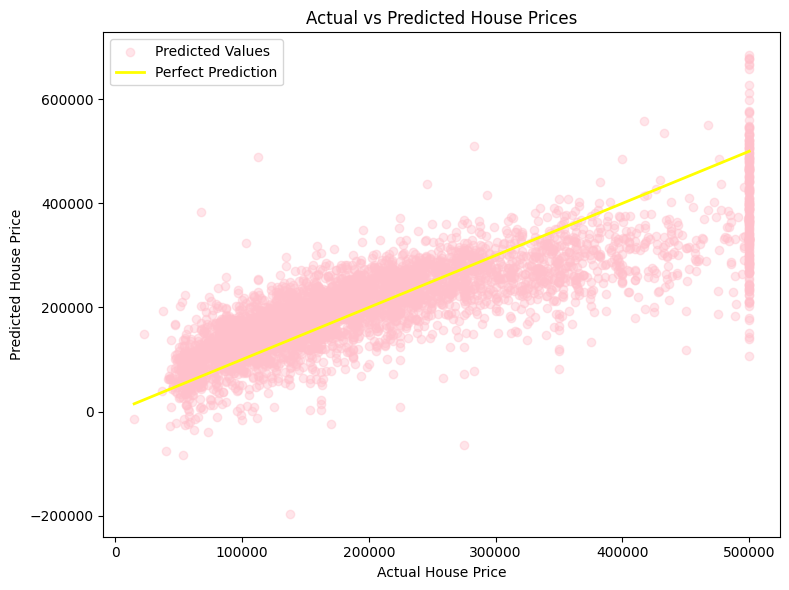

In [ ]:
# Actual vs Predicted
plt.figure(figsize=(8, 6))
# Actual vs Predicted points
plt.scatter(
    y_test,
    y_pred,
    color="pink",
    alpha=0.4,
    label="Predicted Values"
)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="yellow",
    linewidth=2,
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
#saved model
joblib.dump(
    model,
    "house_price_linear_regression.pkl"
)
print("\nModel saved successfully!")



Model saved successfully!


In [ ]:
loaded_model = joblib.load(
    "house_price_linear_regression.pkl"
)
print("Model loaded successfully!")


Model loaded successfully!


In [ ]:
new_house = pd.DataFrame({
    "longitude": [-122.23],
    "latitude": [37.88],
    "housing_median_age": [30],
    "total_rooms": [2000],
    "total_bedrooms": [400],
    "population": [800],
    "households": [350],
    "median_income": [5.0]
})

prediction = loaded_model.predict(new_house)

print("\n")
print("EXAMPLE PREDICTION")
print("")
print(
    "Predicted House Price: $",
    round(prediction[0], 2)
)



EXAMPLE PREDICTION

Predicted House Price: $ 277857.8
